# MuscleMap hands-on: segmenting a lumbar spine MRI

In this notebook you run MuscleMap on the example image that comes with this repository and look at the result.

1. Load the image and view the slices
2. Run `mm_segment`
3. Read the MuscleMap log
4. View the segmentation as an overlay and in 3D

**Before you start:** complete *Option 1 — Terminal* of the installation in the README, then start JupyterLab from the MuscleMap environment, inside the repository folder:

```
conda activate MuscleMap
python -m pip install jupyterlab ipykernel
python -m ipykernel install --user --name musclemap --display-name "Python (MuscleMap)"
cd <path to this repository>
jupyter lab
```

Open this notebook and check that the kernel shown in the top-right corner is **Python (MuscleMap)**. If not, choose it under *Kernel → Change Kernel*. Run the cells one by one with **Shift + Enter**.

## 1. Setup

In [1]:
import json
import os
import shutil
import subprocess
import sys
from pathlib import Path

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# Locate the repository root (the folder that contains data/MuscleMap), starting from this notebook
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "MuscleMap").is_dir())
image_path = repo_root / "data" / "MuscleMap" / "sub-01_T2w_L4-L5.nii.gz"
print("Repository:", repo_root)
print("Image:     ", image_path)
assert image_path.exists(), "Example image not found. Is this notebook inside the workshop repository?"

# The notebook must run on the MuscleMap kernel (Kernel menu > Change Kernel > Python (MuscleMap))
print("Kernel:    ", sys.executable)
if "MuscleMap" not in sys.executable:
    print("WARNING: this is not the MuscleMap kernel. Use Kernel > Change Kernel > Python (MuscleMap).")

# mm_segment lives next to the kernel's Python: <env>/Scripts on Windows, <env>/bin on macOS and Linux
env_dir = Path(sys.executable).parent
candidates = [env_dir / "Scripts" / "mm_segment.exe", env_dir / "mm_segment", shutil.which("mm_segment")]
mm_segment = next((str(c) for c in candidates if c and Path(c).exists()), None)
print("mm_segment:", mm_segment or "NOT FOUND - is MuscleMap installed in this environment (pip install -e .)?")

Repository: C:\Users\EddoWesselink\Stanford_Musculoskeletal_Imaging_Workshop
Image:      C:\Users\EddoWesselink\Stanford_Musculoskeletal_Imaging_Workshop\data\MuscleMap\sub-01_T2w_L4-L5.nii.gz
Kernel:     C:\Users\EddoWesselink\anaconda3\envs\MuscleMap\python.exe
mm_segment: C:\Users\EddoWesselink\anaconda3\envs\MuscleMap\Scripts\mm_segment.exe


## 2. Load and view the image

The example image is an axial T2-weighted MRI of the lumbar spine at the L4–L5 disc: four slices of 4.4 mm, 0.69 mm in-plane.

Shape (x, y, z): (320, 320, 4)
Voxel size (mm): (0.69, 0.69, 4.4)
Orientation:     ('L', 'A', 'S')


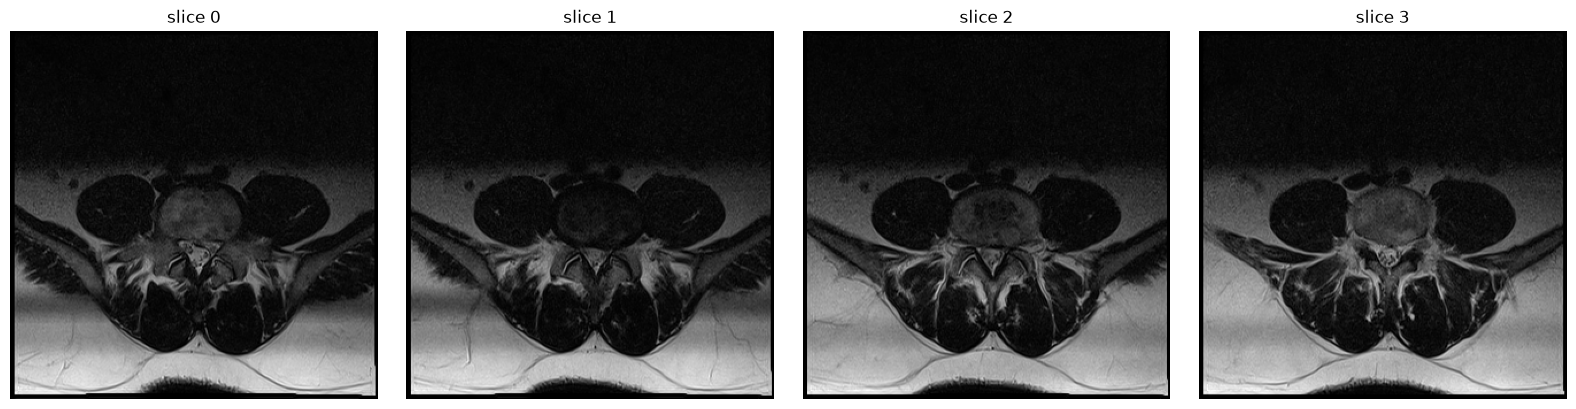

In [2]:
img = nib.load(image_path)
data = img.get_fdata()
voxel = img.header.get_zooms()

print("Shape (x, y, z):", data.shape)
print("Voxel size (mm):", tuple(round(float(v), 2) for v in voxel))
print("Orientation:    ", nib.aff2axcodes(img.affine))

n_slices = data.shape[2]
fig, axes = plt.subplots(1, n_slices, figsize=(4 * n_slices, 4))
for k, ax in enumerate(axes):
    ax.imshow(data[:, :, k].T, cmap="gray", origin="lower")   # anterior at the top, patient's right on the left
    ax.set_title(f"slice {k}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Run MuscleMap

`mm_segment` takes the image (`-i`) and the model (`-r`). The whole-body model segments 113 muscles and bones and works on any contrast. The segmentation is written next to the input image as `sub-01_T2w_L4-L5_dseg.nii.gz`, with a JSON sidecar that records the model version and settings.

The first run downloads the model weights from Zenodo. MuscleMap uses the GPU when it finds one and the CPU otherwise. The log below shows which.

In [3]:
output_dir = image_path.parent        # write the segmentation next to the input image
command = [mm_segment, "-i", str(image_path), "-r", "wholebody", "-o", str(output_dir)]
print("Running:\n\n   " + " ".join(command) + "\n")

# Jupyter sets MPLBACKEND to its inline plotting backend; mm_segment must not inherit that
env = {**os.environ, "MPLBACKEND": "Agg"}

log_lines = []
process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
for line in process.stdout:          # stream the MuscleMap log while it runs
    print(line, end="")
    log_lines.append(line)
process.wait()

print(f"\nmm_segment finished with exit code {process.returncode}")

Running:

   C:\Users\EddoWesselink\anaconda3\envs\MuscleMap\Scripts\mm_segment.exe -i C:\Users\EddoWesselink\Stanford_Musculoskeletal_Imaging_Workshop\data\MuscleMap\sub-01_T2w_L4-L5.nii.gz -r wholebody -o C:\Users\EddoWesselink\Stanford_Musculoskeletal_Imaging_Workshop\data\MuscleMap

2026-10-26 21:34:41,007 - INFO - ------------------------------------------------------------
2026-10-26 21:34:41,010 - INFO - Processing using cuda or cpu: cpu
2026-10-26 21:34:41,012 - INFO - Processing on a CPU will slow down inference speed
2026-10-26 21:34:41,013 - INFO - Checking if image 'C:\Users\EddoWesselink\Stanford_Musculoskeletal_Imaging_Workshop\data\MuscleMap\sub-01_T2w_L4-L5.nii.gz' exists and is readable...
2026-10-26 21:34:41,013 - INFO - Loading configuration file...
2026-10-26 21:34:41,013 - INFO - Contacting Zenodo to resolve 'wholebody' model version...
2026-10-26 21:34:41,638 - INFO - Using cached 'wholebody' model v1.4.
2026-10-26 21:34:41,640 - INFO - Task: Segmentation  |  Regi

## 4. Output files

MuscleMap writes two files next to the input image. The JSON sidecar documents how the segmentation was made.

In [4]:
seg_path = image_path.with_name(image_path.name.replace(".nii.gz", "_dseg.nii.gz"))
json_path = seg_path.with_name(seg_path.name.replace(".nii.gz", ".json"))

for p in (seg_path, json_path):
    print(("found    " if p.exists() else "MISSING  "), p.name)

print()
print(json.dumps(json.loads(json_path.read_text()), indent=2))

found     sub-01_T2w_L4-L5_dseg.nii.gz
found     sub-01_T2w_L4-L5_dseg.json

{
  "input_image": "C:\\Users\\EddoWesselink\\Stanford_Musculoskeletal_Imaging_Workshop\\data\\MuscleMap\\sub-01_T2w_L4-L5.nii.gz",
  "output_image": "sub-01_T2w_L4-L5_dseg.nii.gz",
  "datetime": "2026-10-26T20:34:53+00:00",
  "region": "wholebody",
  "model": "contrast_agnostic_wholebody_model.pth",
  "model_version": 1.4,
  "overlap_percent": 90,
  "chunk_size": "auto",
  "device": "cpu",
  "inferer": {
    "spatial_dim": 2,
    "roi_size": [
      256,
      256
    ],
    "sw_batch_size": 1,
    "overlap": 0.9,
    "mode": "gaussian",
    "sigma_scale": 0.125,
    "padding_mode": "constant",
    "cval": 0.0
  }
}


## 5. View the segmentation

Each voxel in the segmentation holds a label number. The table of all 113 MuscleMap labels is on the [MuscleMap website](https://musclemap.github.io/MuscleMap/muscle-anatomy/); the dictionary below maps the numbers to names.

In [5]:
LABELS = {
    1101: "Left Levator Scapulae",
    1102: "Right Levator Scapulae",
    1111: "Left Semispinalis Cervicis and Multifidus",
    1112: "Right Semispinalis Cervicis and Multifidus",
    1121: "Left Semispinalis Capitis",
    1122: "Right Semispinalis Capitis",
    1131: "Left Splenius Capitis",
    1132: "Right Splenius Capitis",
    1141: "Left Sternocleidomastoid",
    1142: "Right Sternocleidomastoid",
    1151: "Left Longus Colli",
    1152: "Right Longus Colli",
    1161: "Left Trapezius",
    1162: "Right Trapezius",
    2101: "Left Supraspinatus",
    2102: "Right Supraspinatus",
    2111: "Left Subscapularis",
    2112: "Right Subscapularis",
    2121: "Left Infraspinatus",
    2122: "Right Infraspinatus",
    2141: "Left Deltoid",
    2142: "Right Deltoid",
    4101: "Left Rhomboid",
    4102: "Right Rhomboid",
    5101: "Left Thoracolumbar Multifidus",
    5102: "Right Thoracolumbar Multifidus",
    5111: "Left Erector Spinae",
    5112: "Right Erector Spinae",
    5121: "Left Psoas Major",
    5122: "Right Psoas Major",
    5131: "Left Quadratus Lumborum",
    5132: "Right Quadratus Lumborum",
    5141: "Left Latissimus Dorsi",
    5142: "Right Latissimus Dorsi",
    6101: "Left Gluteus Minimus",
    6102: "Right Gluteus Minimus",
    6111: "Left Gluteus Medius",
    6112: "Right Gluteus Medius",
    6121: "Left Gluteus Maximus",
    6122: "Right Gluteus Maximus",
    6131: "Left Tensor Fasciae Latae",
    6132: "Right Tensor Fasciae Latae",
    6141: "Left Iliacus",
    6142: "Right Iliacus",
    6151: "Left Ilium",
    6152: "Right Ilium",
    6160: "Sacrum",
    6171: "Left Femur",
    6172: "Right Femur",
    6181: "Left Piriformis",
    6182: "Right Piriformis",
    6191: "Left Pectineus",
    6192: "Right Pectineus",
    6201: "Left Obturator Internus",
    6202: "Right Obturator Internus",
    6211: "Left Obturator Externus",
    6212: "Right Obturator Externus",
    6221: "Left Gemelli and Quadratus Femoris",
    6222: "Right Gemelli and Quadratus Femoris",
    7101: "Left Vastus Lateralis",
    7102: "Right Vastus Lateralis",
    7111: "Left Vastus Intermedius",
    7112: "Right Vastus Intermedius",
    7121: "Left Vastus Medialis",
    7122: "Right Vastus Medialis",
    7131: "Left Rectus Femoris",
    7132: "Right Rectus Femoris",
    7141: "Left Sartorius",
    7142: "Right Sartorius",
    7151: "Left Gracilis",
    7152: "Right Gracilis",
    7161: "Left Semimembranosus",
    7162: "Right Semimembranosus",
    7171: "Left Semitendinosus",
    7172: "Right Semitendinosus",
    7181: "Left Biceps Femoris Long Head",
    7182: "Right Biceps Femoris Long Head",
    7191: "Left Biceps Femoris Short Head",
    7192: "Right Biceps Femoris Short Head",
    7201: "Left Adductor Magnus",
    7202: "Right Adductor Magnus",
    7211: "Left Adductor Longus",
    7212: "Right Adductor Longus",
    7221: "Left Adductor Brevis",
    7222: "Right Adductor Brevis",
    7231: "Left Patella",
    7232: "Right Patella",
    8101: "Left Tibialis Anterior",
    8102: "Right Tibialis Anterior",
    8111: "Left Tibialis Posterior",
    8112: "Right Tibialis Posterior",
    8121: "Left Peroneus Longus",
    8122: "Right Peroneus Longus",
    8131: "Left Soleus",
    8132: "Right Soleus",
    8141: "Left Medial Gastrocnemius",
    8142: "Right Medial Gastrocnemius",
    8151: "Left Lateral Gastrocnemius",
    8152: "Right Lateral Gastrocnemius",
    8161: "Left Tibia",
    8162: "Right Tibia",
    8171: "Left Fibula",
    8172: "Right Fibula",
    8181: "Left Flexor Hallucis Longus",
    8182: "Right Flexor Hallucis Longus",
    8191: "Left Extensor Digitorum Longus",
    8192: "Right Extensor Digitorum Longus",
    8201: "Left Flexor Digitorum Longus",
    8202: "Right Flexor Digitorum Longus",
    8211: "Left Popliteus",
    8212: "Right Popliteus",
    8221: "Left Plantaris",
    8222: "Right Plantaris",
}

14 structures found in this image:
  5101  Left Thoracolumbar Multifidus  (11002 voxels)
  5102  Right Thoracolumbar Multifidus  (10225 voxels)
  5111  Left Erector Spinae  (10606 voxels)
  5112  Right Erector Spinae  (10302 voxels)
  5121  Left Psoas Major  (13556 voxels)
  5122  Right Psoas Major  (12567 voxels)
  5131  Left Quadratus Lumborum  (516 voxels)
  5132  Right Quadratus Lumborum  (742 voxels)
  6111  Left Gluteus Medius  (4696 voxels)
  6112  Right Gluteus Medius  (2963 voxels)
  6141  Left Iliacus  (1765 voxels)
  6142  Right Iliacus  (1582 voxels)
  6151  Left Ilium  (4040 voxels)
  6152  Right Ilium  (2849 voxels)


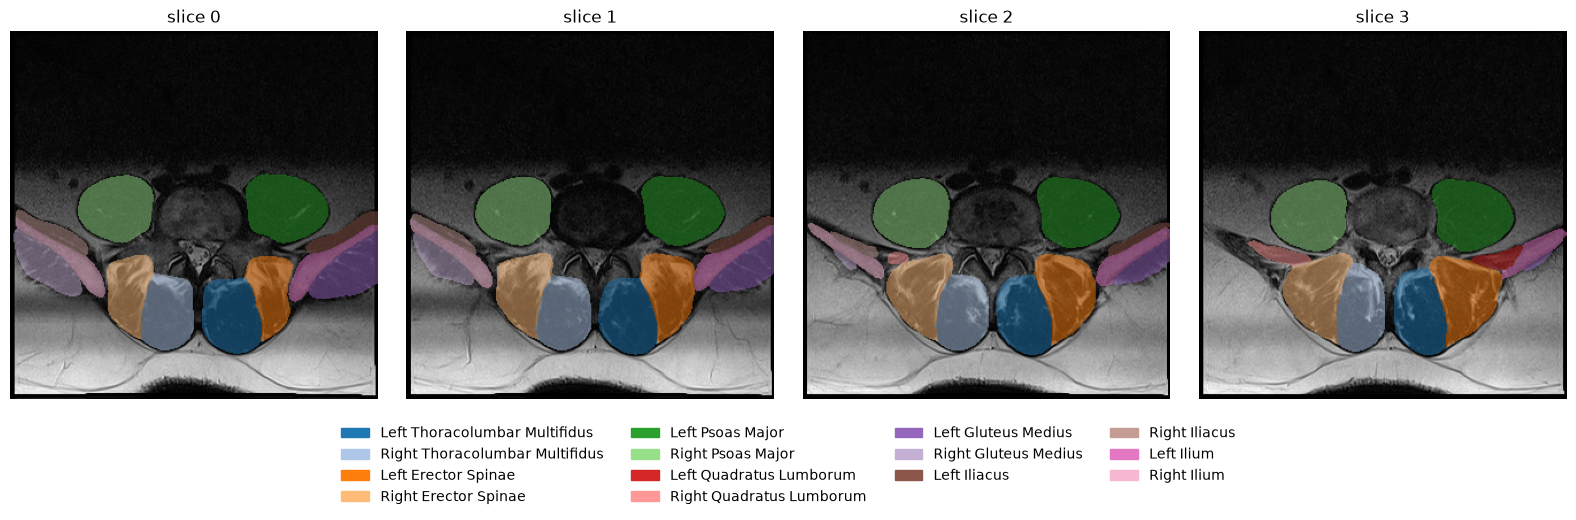

In [6]:
seg = nib.load(seg_path).get_fdata().astype(int)
present = [int(v) for v in np.unique(seg) if v != 0]
print(f"{len(present)} structures found in this image:")
for v in present:
    print(f"  {v}  {LABELS.get(v, 'unknown')}  ({int((seg == v).sum())} voxels)")

# One colour per structure
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

palette = plt.cm.tab20(np.linspace(0, 1, 20))
colors = {v: palette[i % 20] for i, v in enumerate(present)}

def overlay(ax, k, alpha=0.5):
    """Draw slice k of the image with the segmentation on top."""
    ax.imshow(data[:, :, k].T, cmap="gray", origin="lower")
    rgba = np.zeros(seg.shape[:2] + (4,))
    for v, c in colors.items():
        rgba[seg[:, :, k] == v] = c
    rgba[..., 3] *= alpha
    ax.imshow(np.transpose(rgba, (1, 0, 2)), origin="lower")
    ax.axis("off")

fig, axes = plt.subplots(1, n_slices, figsize=(4 * n_slices, 4))
for k, ax in enumerate(axes):
    overlay(ax, k)
    ax.set_title(f"slice {k}")
handles = [Patch(color=colors[v], label=LABELS.get(v, str(v))) for v in present]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.0), frameon=False)
plt.tight_layout()
plt.show()

## 6. 3D rendering

Left: the middle slice with the overlay. Right: a 3D surface of every structure, built with marching cubes. With only four slices the volume is a thin slab, so the view is tilted to show the thickness.

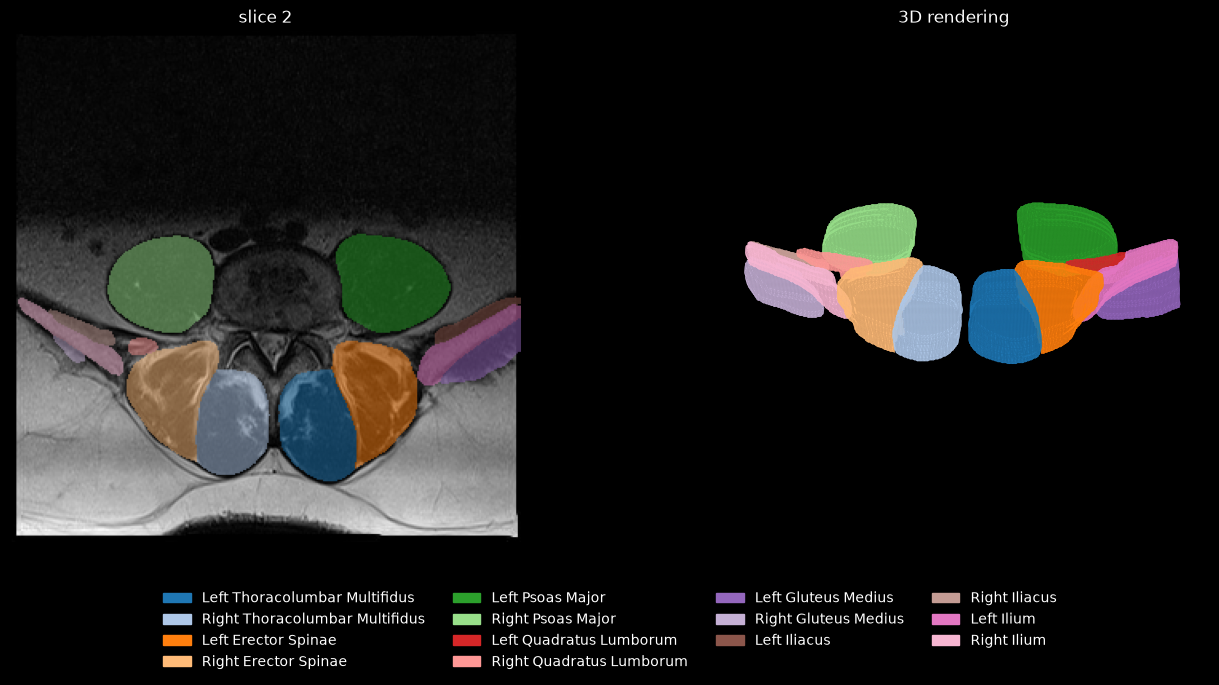

In [7]:
from skimage import measure
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(14, 7), facecolor="black")

# Left: overlay of the middle slice
ax2d = fig.add_subplot(1, 2, 1)
overlay(ax2d, n_slices // 2)
ax2d.set_title(f"slice {n_slices // 2}", color="white")

# Right: 3D surfaces, one per structure
ax3d = fig.add_subplot(1, 2, 2, projection="3d", facecolor="black")
spacing = tuple(float(v) for v in voxel)
for v, c in colors.items():
    mask = np.pad(seg == v, 1)                       # pad so surfaces close at the volume edge
    if mask.sum() < 20:
        continue
    verts, faces, _, _ = measure.marching_cubes(mask.astype(np.uint8), level=0.5, spacing=spacing)
    mesh = Poly3DCollection(verts[faces], alpha=0.95)
    mesh.set_facecolor(c)
    mesh.set_edgecolor("none")
    ax3d.add_collection3d(mesh)

# Zoom in on the segmented structures (in mm), keeping the true proportions
idx = np.argwhere(seg > 0)
lo = (idx.min(axis=0) - 5) * np.array(spacing)
hi = (idx.max(axis=0) + 7) * np.array(spacing)
ax3d.set_xlim(lo[0], hi[0]); ax3d.set_ylim(lo[1], hi[1]); ax3d.set_zlim(lo[2], hi[2])
ax3d.set_box_aspect(hi - lo)
ax3d.view_init(elev=40, azim=-90)                 # same orientation as the 2D view, tilted to show the slab
ax3d.set_axis_off()
ax3d.set_title("3D rendering", color="white")

handles = [Patch(color=colors[v], label=LABELS.get(v, str(v))) for v in present]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.0), frameon=False, labelcolor="white")
fig.subplots_adjust(left=0.02, right=0.98, top=0.93, bottom=0.2, wspace=0.05)
plt.show()

## 7. Next step: quantify

With the segmentation in place, `mm_extract_metrics` computes volume and fat-related measures per structure. For a T2-weighted image, this uses Gaussian mixture modelling to separate muscle from fat:

```
mm_extract_metrics -m gmm -r wholebody -i sub-01_T2w_L4-L5.nii.gz -s sub-01_T2w_L4-L5_dseg.nii.gz -c 3
```

Run it in the terminal from the `data/MuscleMap` folder. The results are written as a CSV next to the image.